In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from Graphs import Node, Edge, FlowGraph

In [5]:
portland = Node(name="Portland", supply=200, type="factory", x=0, y=1)
flint = Node(name="Flint", supply=600, type="factory", x=0, y=0)
los_angeles = Node(name="Los Angeles", demand=300, type="facility", x=1, y=1)
hawkins = Node(name="Hawkins", demand=400, type="facility", x=1, y=0)

nodes = [portland, flint, los_angeles, hawkins]

edges = [
    Edge(origin=portland, destination=los_angeles, variable_cost=30),
    Edge(origin=portland, destination=hawkins, variable_cost=40),
    Edge(origin=flint, destination=los_angeles, variable_cost=60),
    Edge(origin=flint, destination=hawkins, variable_cost=50),
]

graph = FlowGraph(nodes, edges)

In [6]:
status = graph.min_cost_flow()

Model creation time: 0.02 s
Optimal solution found: 32000.00 in 0.03 s


In [9]:
if status == "Optimal":
    shipments = pd.DataFrame(
        [(u, v, d["variable_cost"], d["flow"], d["variable_cost"] * d["flow"]) for u, v, d in graph.edges(data=True)],
        columns=["from", "to", "cost/unit (euro)", "units", "cost (euro)"],
    )
    display(shipments)

    factories = pd.DataFrame(
        [(n, d["supply"], sum(graph.edges[n, v]["flow"] for v in graph.successors(n)))
         for n, d in graph.nodes(data=True) if d["type"] == "factory"],
        columns=["factory", "supply", "shipped"],
    )
    display(factories)

    print("Total cost:", graph.result.objective, "euro")

,from,to,cost/unit (euro),units,cost (euro)
0,Portland,Los Angeles,30.0,200.0,6000.0
1,Portland,Hawkins,40.0,0.0,0.0
2,Flint,Los Angeles,60.0,100.0,6000.0
3,Flint,Hawkins,50.0,400.0,20000.0


,factory,supply,shipped
0,Portland,200.0,200.0
1,Flint,600.0,500.0


Total cost: 32000.0 euro


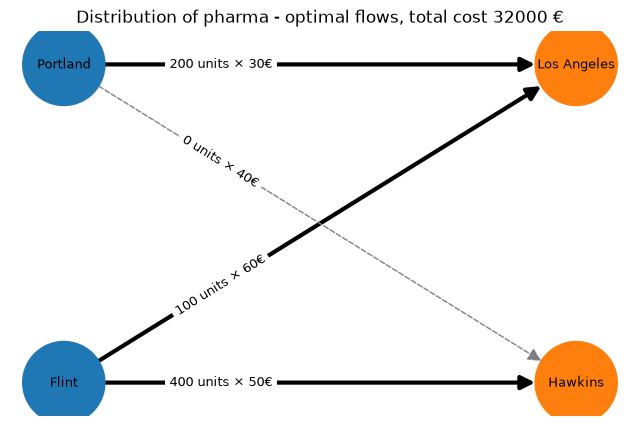

In [8]:
pos = {n: (d["x"], d["y"]) for n, d in graph.nodes(data=True)}
colors = ["tab:blue" if d["type"] == "factory" else "tab:orange" for _, d in graph.nodes(data=True)]

used = [(u, v) for u, v, d in graph.edges(data=True) if d["flow"] > 0]
unused = [(u, v) for u, v, d in graph.edges(data=True) if d["flow"] == 0]
labels = {(u, v): f"{d['flow']:.0f} units × {d['variable_cost']:.0f}€" for u, v, d in graph.edges(data=True)}

fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx_nodes(graph, pos, node_color=colors, node_size=3500, ax=ax)
nx.draw_networkx_labels(graph, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(graph, pos, edgelist=used, width=3, arrowsize=20, node_size=3500, ax=ax)
nx.draw_networkx_edges(graph, pos, edgelist=unused, style="dashed", edge_color="grey", arrowsize=20, node_size=3500, ax=ax)
nx.draw_networkx_edge_labels(graph, pos, edge_labels=labels, label_pos=0.3, font_size=9, ax=ax)
ax.set_title(f"Distribution of pharma - optimal flows, total cost {graph.result.objective:.0f} €")
ax.axis("off")
plt.show()